# Приближенный вариационный вывод
Задача: выявить распределение (степень неопределенности обусловнное неучтенными факторами, такими как конкуренты, акции и пр) средних продаж для каждого среза цены 

Метод решения:
1. Создаем симуляцию с зараннее заданными параметрами (скрытыми переменными)
2. По результатам симуляции и определеяем эти параметры (скрытыие переменные)
3. Если удастся получить параметры симуляции близкие к заданным, мы можем рассчитывать на то, что в реальных данных определяемые нами скрытые параметры будут также близки к фактическим

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.optim as optim
from scipy.stats import gamma
from torch.distributions import Gamma, Poisson
from scipy.optimize import curve_fit

Симуляция стационарных продаж ($\lambda$ = const для каждого среза цены)

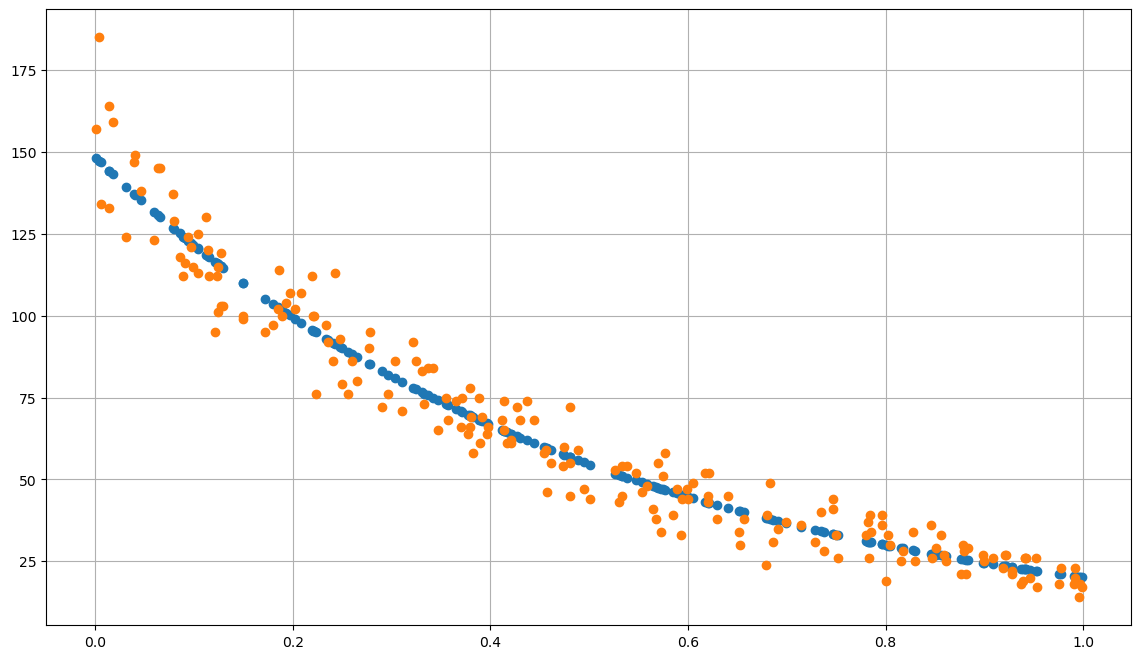

In [3]:
fig, ax = plt.subplots(figsize=(14, 8))
N = 200
p = np.random.rand(N)
a = -2
b = 5
t = np.exp(a * p + b)
order = np.random.poisson(t)
plt.plot(p, t, "o")
plt.plot(p, order, "o")
plt.grid(True)


Симуляция нестационарных продаж. Тепреь $\lambda$ (средние продажи) приходит из Гамма распределения

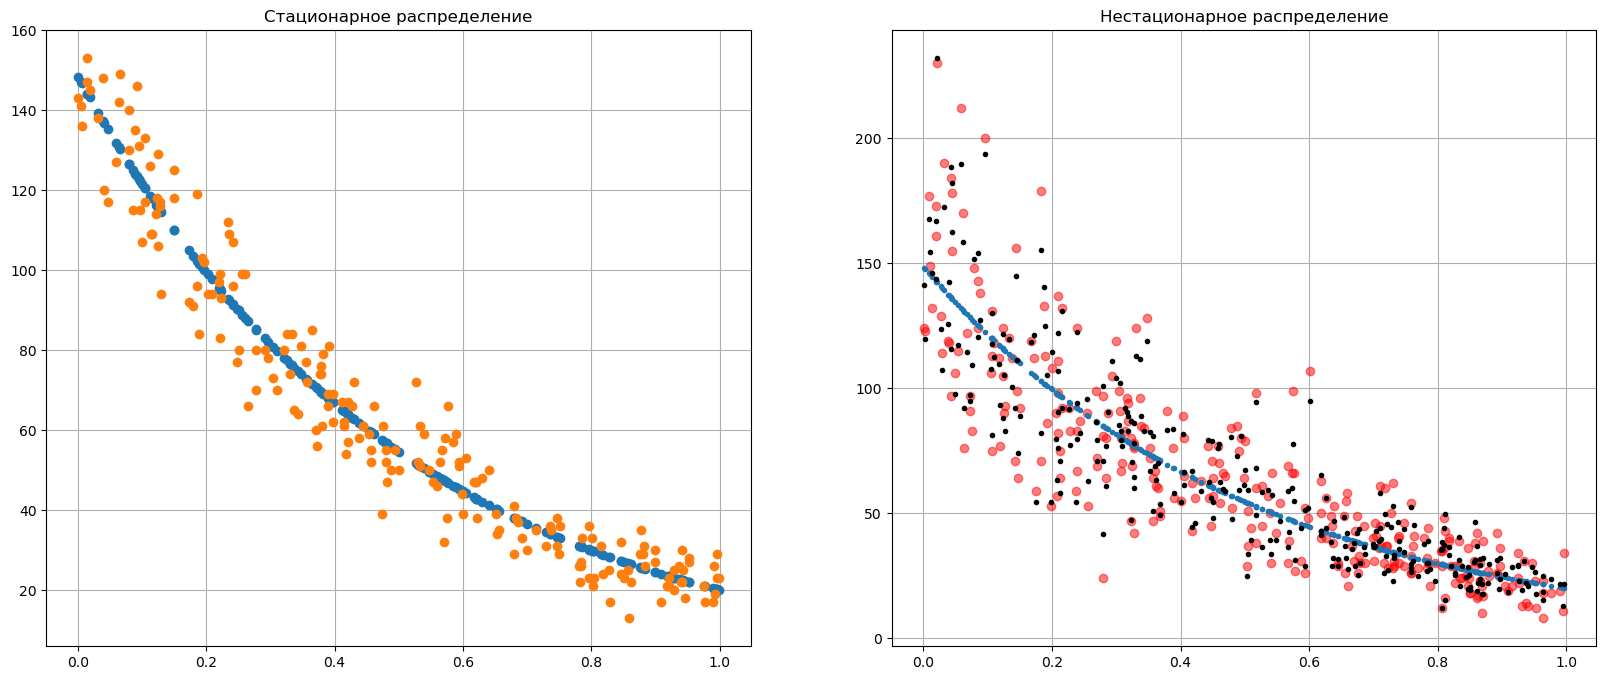

In [4]:
W0, W1, W2 = 1, 0.5, 0.05


def get_data(a=-2, b=5, w0=W0, w1=W1, w2=W2, N=300):
    """ """
    p = np.random.rand(N)
    E = np.exp(a * p + b)
    D = w0 + E * w1 + E**2 * w2
    shape = E**2 / D
    scale = D / E
    g = np.random.gamma(shape, scale)
    pois = np.random.poisson(g)
    return pois, g, E, p, shape, scale, D


fig, ax = plt.subplots(1, 2, figsize=(20, 8))
t = np.exp(a * p + b)
order = np.random.poisson(t)
ax[0].plot(p, t, "o")
ax[0].plot(p, order, "o")
ax[0].grid(True)
ax[0].set_title("Стационарное распределение")
poes, t, e, p, shape, scale, d = get_data()
# plt.plot(p,t,'.')
# plt.plot(p,e,'.')
ax[1].plot(p, poes, "or", alpha=0.5)
ax[1].plot(p, e, ".")
ax[1].plot(p, t, ".k")
ax[1].set_title("Нестационарное распределение")
ax[1].grid(True);


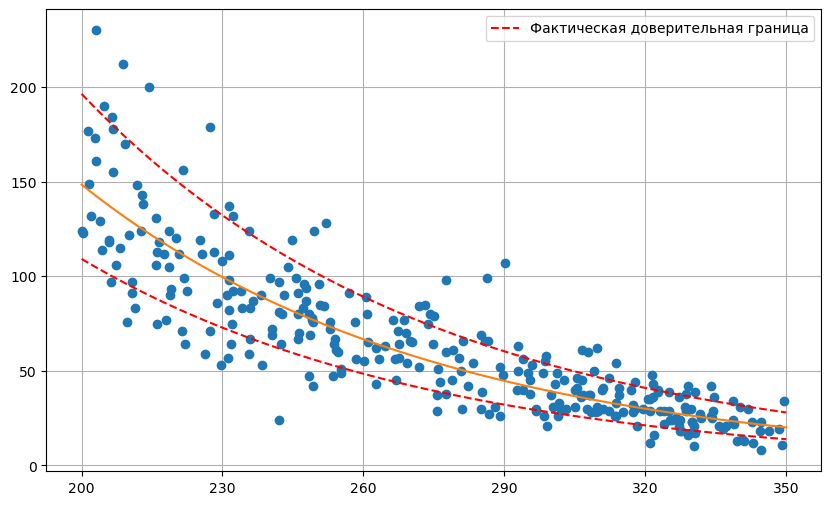

In [13]:
def get_params(Y, ww0, ww1, ww2):
    t = (ww0 + ww1 * Y + ww2 * Y**2) / Y
    k = Y**2 / (ww0 + ww1 * Y + ww2 * Y**2)
    return t, k


x = np.linspace(0, 1)
Y = np.exp(-2 * x + 5)
t, k =  get_params(Y, W0, W1, W2)
y_up = np.zeros(50)
y_down = np.zeros(50)
y_up_real = np.zeros(50)
y_down_real = np.zeros(50)
for i in range(50):
    #p80 = gamma.ppf([0.1, 0.5, 0.9], a=k, scale=t)
    #f = np.diff(p80)
    #y_up[i] = Y[i] + f[1]
    #y_down[i] = Y[i] - f[0]

    t_real, k_real = get_params(Y[i], W0, W1, W2)
    p80_real = gamma.ppf([0.1, 0.5, 0.9], a=k_real, scale=t_real)
    f_real = np.diff(p80_real)
    y_up_real[i] = Y[i] + f_real[1]
    y_down_real[i] = Y[i] - f_real[0]

plt.figure(figsize=(10, 6))
plt.plot(p, poes, "o")
plt.plot(x, Y)
# plt.plot( x, y_up, "*-k", linewidth=3, label="Доверительная граница полученная в результате оптимизации")
# plt.plot(x, y_down, "*-k", linewidth=3)
plt.plot(x, y_up_real, "--r", label="Фактическая доверительная граница")
plt.plot(x, y_down_real, "--r")
plt.grid(True)
plt.legend()
plt.xticks([0, 0.2, 0.4, 0.6, 0.8, 1], [200, 230, 260, 290, 320, 350]);

Пусть $\lambda$ имеет распределение
$$ p(\lambda|k,\theta) = Gamma(k,\theta)$$
Мат ожидание и дисперсия выражается через $k$, $\theta$
$$ \mathbb E[\lambda] = k\theta, \mathbb D[\lambda] = k\theta^2 $$
$$ k = \frac{\mathbb E[\lambda]}{\mathbb{D[\lambda]}} ,  \theta = \frac{\mathbb{D[\lambda]}}{\mathbb E^2[\lambda]} \tag{1} $$




Полагая, что $\mathbb E[\lambda]$ мы оценили моделью, введем зависимость дисперсии данных от $\lambda$
$$ \mathbb D[\lambda] = w_0 + w_1\lambda + w_2\lambda^2 $$
Выражение (1) с учетом последнего
$$ k = \frac{\mathbb E[\lambda]}{ w_0 + w_1\lambda + w_2\lambda^2} ,  \theta = \frac{ w_0 + w_1\lambda+ w_2\lambda^2}{\mathbb E^2[\lambda]} \tag{2} $$
Тогда, Байесовский вывод

$$p(k,\theta|o) = \frac{p(o|\lambda)p(\lambda|k,\theta)p(w_0)p(w_1)p(w_2)}{\int\int p(o|\lambda)p(\lambda|k,\theta)p(w_0)p(w_1)p(w_2)dw_0 dw_1 dw_2}$$

## ELBO
$$ ELBO = \ln p(o|\lambda) + \ln p(\lambda|k,\theta) + \ln p(w_0)+ \ln p(w_1) + \ln p(w_2) +H[q(w_0)] + H[q[w_1)] + H[q[w_2)]+ H[q(\lambda)]$$
$$ \ln p(\lambda|k,\theta) = \sum_i \ln Gamma(\lambda_i|k_i,\theta_i) $$

In [9]:
# get_data(a=-2,b=3,w0=1,w1=0.5,w2 = 0.05,N=300)
poes, t, e, p, shape, scale, d = get_data(a=-2, b=5, N=200)

In [10]:
def func(price, a, b):
    return np.exp(a * price +b) 

popt, pcov = curve_fit(func, p, poes)


E = func(p, popt[0], popt[1])

Для нахождения параметров $w_0$ и $w_1$ применяестя приближенный байесовский вывод. В этом выводе мы оптимизируем нижнюю границу доказательства (Evidence lower bound) [ELBO](https://en.wikipedia.org/wiki/Evidence_lower_bound)

Задаем начальные значения для всех искомых параметров

In [ ]:
w0_mu = torch.tensor(1.0, dtype=torch.float, requires_grad=True)
w0_scale = torch.tensor(1.0, dtype=torch.float, requires_grad=True)

w1_mu = torch.tensor(1.0, dtype=torch.float, requires_grad=True)
w1_scale = torch.tensor(1.0, dtype=torch.float, requires_grad=True)


w2_mu = torch.tensor(0.0, dtype=torch.float, requires_grad=True)
w2_scale = torch.tensor(0.0, dtype=torch.float, requires_grad=True)

# Параметры для оптимизации
params = [w0_mu, w0_scale, w1_mu, w1_scale, w2_mu, w2_scale]

E = torch.tensor(E)

data = torch.tensor(poes)
mod_exp = torch.tensor(e, dtype=torch.float)


def get_variational_distributions(E):
    # Вариационное распределение для w0

    w0_mu_e = torch.exp(w0_mu)
    w0_scale_e = torch.exp(w0_scale)
    # print(w0_mu_e,w0_scale_e)
    q_w0 = Gamma(w0_mu_e, w0_scale_e)
    w0 = w0_mu_e * w0_scale_e

    w1_mu_e = torch.exp(w1_mu)
    w1_scale_e = torch.exp(w1_scale)
    q_w1 = Gamma(w1_mu_e, w1_scale_e)
    w1 = w1_mu_e * w1_scale_e

    w2_mu_e = torch.exp(w2_mu)
    w2_scale_e = torch.exp(w2_scale)
    q_w2 = Gamma(w2_mu_e, w2_scale_e)
    w2 = w2_mu_e * w2_scale_e
    
    # Вариационные параметры для lambda_i
    k = E / (w0 + w1 * E + w2 * E * 2)
    theta = (w0 + w1 * E + w2 * E**2) / E**2

    q_lambda = Gamma(k, theta)

    return q_w0, q_w1, q_w2, q_lambda, w0, w1, w2


## Задание 
1. Найти параметры $ k, \theta$
2. Построить доверительный интервал для оценки матожидания спроса найденный из вариационного вывода и сравнить его с фактическим доверительным интервалом 
3. Написать СВОИ выводы 